In [1]:
from ucimlrepo import fetch_ucirepo 
  
# fetch dataset 
predict_students_dropout_and_academic_success = fetch_ucirepo(id=697) 
  
# data (as pandas dataframes) 
X = predict_students_dropout_and_academic_success.data.features 
y = predict_students_dropout_and_academic_success.data.targets 

In [2]:
X.info()
X.describe()

<class 'pandas.DataFrame'>
RangeIndex: 4424 entries, 0 to 4423
Data columns (total 36 columns):
 #   Column                                          Non-Null Count  Dtype  
---  ------                                          --------------  -----  
 0   Marital Status                                  4424 non-null   int64  
 1   Application mode                                4424 non-null   int64  
 2   Application order                               4424 non-null   int64  
 3   Course                                          4424 non-null   int64  
 4   Daytime/evening attendance                      4424 non-null   int64  
 5   Previous qualification                          4424 non-null   int64  
 6   Previous qualification (grade)                  4424 non-null   float64
 7   Nacionality                                     4424 non-null   int64  
 8   Mother's qualification                          4424 non-null   int64  
 9   Father's qualification                          4424

,Marital Status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 1st sem (without evaluations),Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP
count,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,...,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000
mean,1.178571,18.669078,1.727848,8856.642631,0.890823,4.577758,132.613314,1.873192,19.561935,22.275316,...,0.137658,0.541817,6.232143,8.063291,4.435805,10.230206,0.150316,11.566139,1.228029,0.001969
std,0.605747,17.484682,1.313793,2063.566416,0.311897,10.216592,13.188332,6.914514,15.603186,15.343108,...,0.690880,1.918546,2.195951,3.947951,3.014764,5.210808,0.753774,2.663850,1.382711,2.269935
min,1.000000,1.000000,0.000000,33.000000,0.000000,1.000000,95.000000,1.000000,1.000000,1.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,7.600000,-0.800000,-4.060000
25%,1.000000,1.000000,1.000000,9085.000000,1.000000,1.000000,125.000000,1.000000,2.000000,3.000000,...,0.000000,0.000000,5.000000,6.000000,2.000000,10.750000,0.000000,9.400000,0.300000,-1.700000
50%,1.000000,17.000000,1.000000,9238.000000,1.000000,1.000000,133.100000,1.000000,19.000000,19.000000,...,0.000000,0.000000,6.000000,8.000000,5.000000,12.200000,0.000000,11.100000,1.400000,0.320000
75%,1.000000,39.000000,2.000000,9556.000000,1.000000,1.000000,140.000000,1.000000,37.000000,37.000000,...,0.000000,0.000000,7.000000,10.000000,6.000000,13.333333,0.000000,13.900000,2.600000,1.790000
max,6.000000,57.000000,9.000000,9991.000000,1.000000,43.000000,190.000000,109.000000,44.000000,44.000000,...,12.000000,19.000000,23.000000,33.000000,20.000000,18.571429,12.000000,16.200000,3.700000,3.510000


In [3]:
X.head()

,Marital Status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 1st sem (without evaluations),Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP
0,1,17,5,171,1,1,122.0,1,19,12,...,0,0,0,0,0,0.000000,0,10.8,1.4,1.74
1,1,15,1,9254,1,1,160.0,1,1,3,...,0,0,6,6,6,13.666667,0,13.9,-0.3,0.79
2,1,1,5,9070,1,1,122.0,1,37,37,...,0,0,6,0,0,0.000000,0,10.8,1.4,1.74
3,1,17,2,9773,1,1,122.0,1,38,37,...,0,0,6,10,5,12.400000,0,9.4,-0.8,-3.12
4,2,39,1,8014,0,1,100.0,1,37,38,...,0,0,6,6,6,13.000000,0,13.9,-0.3,0.79


Удалить Debtor, Tuition fees up to date, все Curricular units

In [4]:
drop_cols = ["Debtor", "Tuition fees up to date"]
drop_cols += [c for c in X.columns if c.startswith("Curricular units")]

X = X.drop(columns=drop_cols)
X.shape

(4424, 22)

In [5]:
X.duplicated().sum()

np.int64(0)

In [6]:
y["Target"].value_counts()

Target
Graduate    2209
Dropout     1421
Enrolled     794
Name: count, dtype: int64

In [7]:
y["Target"].value_counts(normalize=True) #в долях

Target
Graduate    0.499322
Dropout     0.321203
Enrolled    0.179476
Name: proportion, dtype: float64

In [8]:
from sklearn.model_selection import train_test_split

RANDOM_STATE = 42
TEST_SIZE = 0.10
VAL_SIZE = 0.20

# 10% всех данных оставляем для итоговой оценки.
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X,
    y["Target"],
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y["Target"],
)

# 20 / 90 оставшихся данных = 20% исходной выборки.
# В итоге: примерно 70% train / 20% validation / 10% test.
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val,
    y_train_val,
    test_size=VAL_SIZE / (1 - TEST_SIZE),
    random_state=RANDOM_STATE,
    stratify=y_train_val,
)

for split_name, target in [("train", y_train), ("validation", y_val), ("test", y_test)]:
    print(f"{split_name}: {len(target)} строк ({len(target) / len(y):.1%})")


In [9]:
categorical_features = [
    "Marital Status",
    "Application mode",
    "Course",
    "Daytime/evening attendance",
    "Previous qualification",
    "Nacionality",
    "Mother's qualification",
    "Father's qualification",
    "Mother's occupation",
    "Father's occupation",
    "Displaced",
    "Educational special needs",
    "Gender",
    "Scholarship holder",
    "International",
]

numeric_features = [
    feature
    for feature in X_train.columns
    if feature not in categorical_features
]

In [10]:
#Чтобы принять решение нужно ли скейлить или логарифмировать
X_train[numeric_features].describe()

,Application order,Previous qualification (grade),Admission grade,Age at enrollment,Unemployment rate,Inflation rate,GDP
count,2654.000000,2654.000000,2654.000000,2654.000000,2654.000000,2654.000000,2654.000000
mean,1.743029,132.646383,126.902035,23.200075,11.589751,1.205539,0.010377
std,1.323160,13.130494,14.401136,7.581366,2.664697,1.380507,2.257470
min,1.000000,95.000000,95.000000,17.000000,7.600000,-0.800000,-4.060000
25%,1.000000,124.000000,117.900000,19.000000,9.400000,0.300000,-1.700000
50%,1.000000,133.100000,126.000000,20.000000,11.100000,1.400000,0.320000
75%,2.000000,140.000000,134.700000,25.000000,13.900000,2.600000,1.790000
max,9.000000,190.000000,190.000000,70.000000,16.200000,3.700000,3.510000



Logistic Regression
              precision    recall  f1-score   support

     Dropout       0.59      0.57      0.58       284
    Enrolled       0.47      0.24      0.32       159
    Graduate       0.65      0.78      0.71       442

    accuracy                           0.62       885
   macro avg       0.57      0.53      0.54       885
weighted avg       0.60      0.62      0.60       885

Balanced accuracy: 0.5319142675093027


/Users/maksim/Library/Python/3.14/lib/python/site-packages/sklearn/preprocessing/_encoders.py:262: UserWarning: Found unknown categories in columns [1, 4, 5, 6, 7, 8, 9] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


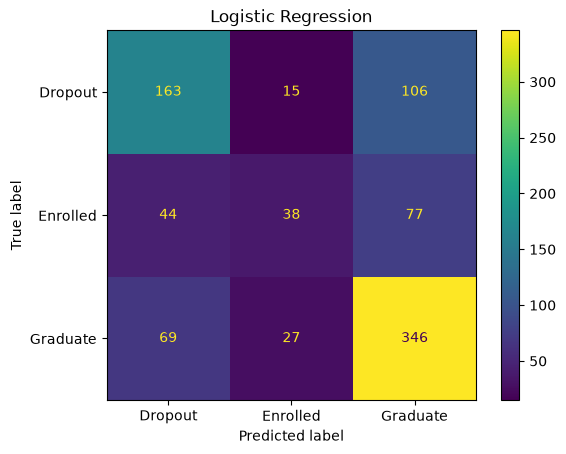

/Users/maksim/Library/Python/3.14/lib/python/site-packages/sklearn/preprocessing/_encoders.py:262: UserWarning: Found unknown categories in columns [1, 4, 5, 6, 7, 8, 9] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)



Decision Tree
              precision    recall  f1-score   support

     Dropout       0.46      0.46      0.46       284
    Enrolled       0.25      0.27      0.26       159
    Graduate       0.61      0.60      0.61       442

    accuracy                           0.49       885
   macro avg       0.44      0.44      0.44       885
weighted avg       0.50      0.49      0.50       885

Balanced accuracy: 0.44257808058592785


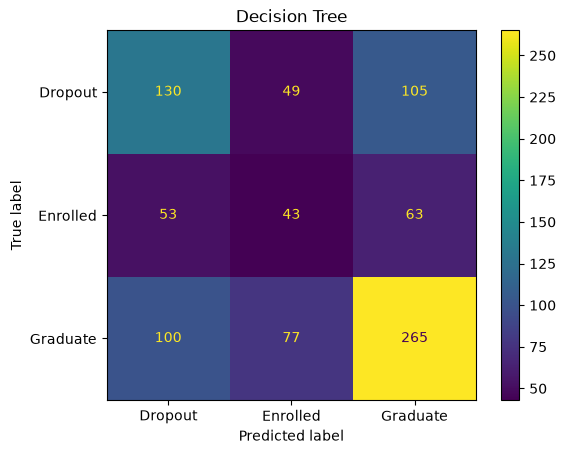

/Users/maksim/Library/Python/3.14/lib/python/site-packages/sklearn/preprocessing/_encoders.py:262: UserWarning: Found unknown categories in columns [1, 4, 5, 6, 7, 8, 9] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)



Dummy
              precision    recall  f1-score   support

     Dropout       0.33      0.34      0.34       284
    Enrolled       0.18      0.17      0.17       159
    Graduate       0.50      0.50      0.50       442

    accuracy                           0.39       885
   macro avg       0.34      0.34      0.34       885
weighted avg       0.39      0.39      0.39       885

Balanced accuracy: 0.3363660576968169


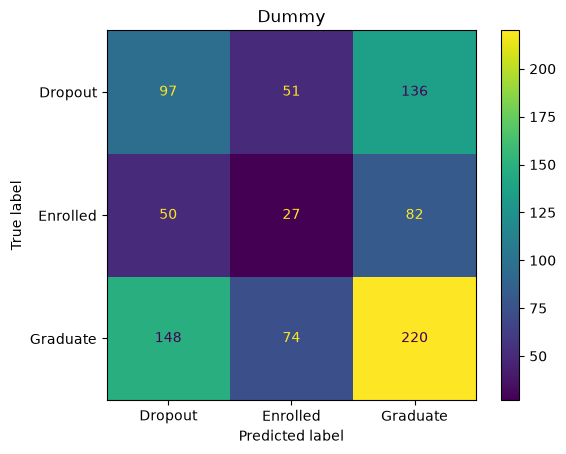

In [11]:
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report, balanced_accuracy_score, ConfusionMatrixDisplay, f1_score

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(drop="if_binary", handle_unknown="ignore"), categorical_features),
    ]
)

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(random_state=RANDOM_STATE),
    "Dummy": DummyClassifier(strategy="stratified", random_state=RANDOM_STATE) #без стратегии стратификации предсказывал только один класс
}

pipelines = {}
scores = {}
for name, model in models.items():
    pipeline = Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("classifier", model),
    ])
    
    pipeline.fit(X_train, y_train)
    y_pred = pipeline.predict(X_val)
    scores[name] = f1_score(y_val, y_pred, average="macro")

    print(f"\n{name}")
    print(classification_report(y_val, y_pred, zero_division=0))
    print("Balanced accuracy:", balanced_accuracy_score(y_val, y_pred))
    ConfusionMatrixDisplay.from_predictions(y_val, y_pred)
    plt.title(name)
    plt.show()

    pipelines[name] = pipeline


In [ ]:
#Считаем лучшую модель на тест выборке
best_name = max(scores, key=scores.get)
best_pipeline = pipelines[best_name]

_test_pred = best_pipeline.predict(X_test)

### Подбор порогов на validation: все три класса

В нашей задаче нужно выбрать один из трёх классов, и для этого уже есть правило: брать класс с максимальной вероятностью — argmax.



До этого использовался обычный `predict()`: выбор самого вероятного класса (argmax), без подбора порогов. Для многоклассовой классификации подбор порогов необязателен; ниже — доп эксперимент.

Подбираем **отдельный порог для каждого класса совместно**, максимизируя **macro-F1 всех трёх классов** на validation:

- Если порог проходит один класс, выбираем его.
- Если проходят несколько классов, выбираем самый вероятный среди прошедших.
- Если не проходит ни один класс, выбираем самый вероятный из всех.

Перебираем сетку от 0.1 до 0.9 с шагом 0.1: для трёх классов это 729 комбинаций. Если пороги не улучшают validation macro-F1, оставляем argmax. Это лучший результат на заданной сетке, а не гарантия глобального оптимума или улучшения на test.

 Для подбора порогов используем только val, которую использовали при заполнении scores. То есть одна и та же validation действительно участвует в двух последовательных решениях: выборе модели и выборе порогов. И это НОРМ!

 P.S: И в бинарной классификации подбирать порог тоже необязательно: можно оставить стандартный 0.5. В обоих случаях порог подбирают под цель, а не просто потому, что это обязательный этап.


In [13]:
import numpy as np
import pandas as pd
from itertools import product
from IPython.display import display


def predict_with_class_thresholds(probabilities, classes, thresholds):
    # Столбцы вероятностей и пороги идут в порядке pipeline.classes_.
    eligible = probabilities >= np.asarray(thresholds)
    eligible_scores = np.where(eligible, probabilities, -np.inf)

    # Если ни один порог не пройден, возвращаем обычный argmax.
    no_eligible_class = ~eligible.any(axis=1)
    eligible_scores[no_eligible_class] = probabilities[no_eligible_class]
    return classes[eligible_scores.argmax(axis=1)]


class_order = best_pipeline.classes_
y_val_proba = best_pipeline.predict_proba(X_val)
y_val_pred_default = best_pipeline.predict(X_val)
val_macro_f1_default = f1_score(
    y_val, y_val_pred_default, labels=class_order, average="macro", zero_division=0
)

threshold_grid = np.linspace(0.1, 0.9, 9)
# Одинаковые пороги 0.5 с описанным fallback дают обычный argmax.
best_thresholds = np.full(len(class_order), 0.5)
best_threshold_score = val_macro_f1_default

for candidate_thresholds in product(threshold_grid, repeat=len(class_order)):
    candidate_pred = predict_with_class_thresholds(
        y_val_proba, class_order, candidate_thresholds
    )
    candidate_score = f1_score(
        y_val, candidate_pred, labels=class_order, average="macro", zero_division=0
    )
    if candidate_score > best_threshold_score:
        best_threshold_score = candidate_score
        best_thresholds = np.asarray(candidate_thresholds)

use_tuned_thresholds = best_threshold_score > val_macro_f1_default
print("Модель:", best_name)
print(f"Validation macro-F1, argmax: {val_macro_f1_default:.4f}")
print(f"Validation macro-F1, выбранное правило: {best_threshold_score:.4f}")
print("Правило:", "подобранные пороги" if use_tuned_thresholds else "argmax")
display(pd.DataFrame({"class": class_order, "threshold": best_thresholds}))

if use_tuned_thresholds:
    y_val_pred_tuned = predict_with_class_thresholds(
        y_val_proba, class_order, best_thresholds
    )
    print("Validation: метрики по классам с подобранными порогами")
    print(classification_report(
        y_val, y_val_pred_tuned, labels=class_order, digits=3, zero_division=0
    ))

/Users/maksim/Library/Python/3.14/lib/python/site-packages/sklearn/preprocessing/_encoders.py:262: UserWarning: Found unknown categories in columns [1, 4, 5, 6, 7, 8, 9] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
/Users/maksim/Library/Python/3.14/lib/python/site-packages/sklearn/preprocessing/_encoders.py:262: UserWarning: Found unknown categories in columns [1, 4, 5, 6, 7, 8, 9] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


Модель: Logistic Regression
Validation macro-F1, argmax: 0.5376
Validation macro-F1, выбранное правило: 0.5532
Правило: подобранные пороги


,class,threshold
0,Dropout,0.6
1,Enrolled,0.3
2,Graduate,0.6


Validation: метрики по классам с подобранными порогами
              precision    recall  f1-score   support

     Dropout      0.602     0.521     0.558       284
    Enrolled      0.396     0.396     0.396       159
    Graduate      0.677     0.735     0.705       442

    accuracy                          0.606       885
   macro avg      0.558     0.551     0.553       885
weighted avg      0.602     0.606     0.603       885



### Итоговые метрики на test

Теперь используем `y_test` для итоговой оценки

Test: Logistic Regression, исходный argmax
              precision    recall  f1-score   support

     Dropout      0.557     0.567     0.562       284
    Enrolled      0.273     0.113     0.160       159
    Graduate      0.643     0.771     0.702       442

    accuracy                          0.588       885
   macro avg      0.491     0.484     0.475       885
weighted avg      0.549     0.588     0.560       885

Macro-F1: 0.4745
Balanced accuracy: 0.4839

Test: пороги, выбранные на validation
              precision    recall  f1-score   support

     Dropout      0.585     0.511     0.545       284
    Enrolled      0.297     0.289     0.293       159
    Graduate      0.649     0.708     0.677       442

    accuracy                          0.569       885
   macro avg      0.510     0.503     0.505       885
weighted avg      0.565     0.569     0.566       885

Macro-F1: 0.5052
Balanced accuracy: 0.5027


/Users/maksim/Library/Python/3.14/lib/python/site-packages/sklearn/preprocessing/_encoders.py:262: UserWarning: Found unknown categories in columns [5, 6, 7, 8, 9] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


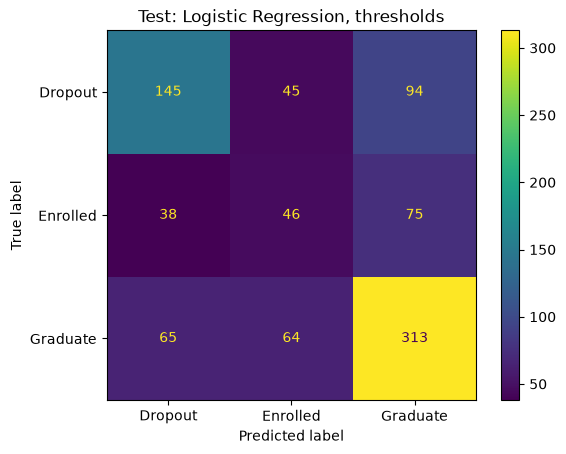

In [14]:
y_test_proba = best_pipeline.predict_proba(X_test)
y_test_pred_final = (
    predict_with_class_thresholds(y_test_proba, class_order, best_thresholds)
    if use_tuned_thresholds
    else y_test_pred.copy()
)

print(f"Test: {best_name}, исходный argmax")
print(classification_report(
    y_test, y_test_pred, labels=class_order, digits=3, zero_division=0
))
print(f"Macro-F1: {f1_score(y_test, y_test_pred, average='macro', zero_division=0):.4f}")
print(f"Balanced accuracy: {balanced_accuracy_score(y_test, y_test_pred):.4f}")

if use_tuned_thresholds:
    print("\nTest: пороги, выбранные на validation")
    print(classification_report(
        y_test, y_test_pred_final, labels=class_order, digits=3, zero_division=0
    ))
    print(f"Macro-F1: {f1_score(y_test, y_test_pred_final, average='macro', zero_division=0):.4f}")
    print(f"Balanced accuracy: {balanced_accuracy_score(y_test, y_test_pred_final):.4f}")

ConfusionMatrixDisplay.from_predictions(
    y_test, y_test_pred_final, labels=class_order
)
plt.title(f"Test: {best_name}, {'thresholds' if use_tuned_thresholds else 'argmax'}")
plt.show()

### Дополнительно: ROC-AUC one-vs-rest на test

Каждый класс по очереди считаем положительным, а остальные два — отрицательными. Показываем ROC-AUC каждого класса и их среднее (macro).

,class,ROC-AUC (OvR)
0,Dropout,0.762239
1,Enrolled,0.660169
2,Graduate,0.740759


Test macro ROC-AUC (OvR): 0.7211


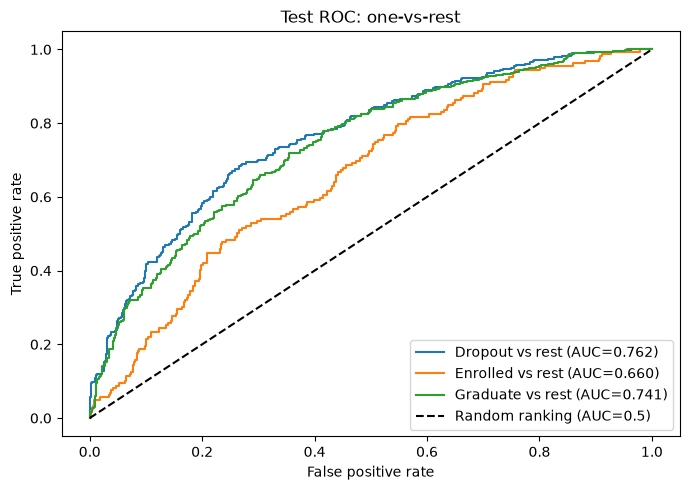

In [15]:
from sklearn.metrics import roc_auc_score, roc_curve

roc_auc_per_class = roc_auc_score(
    y_test,
    y_test_proba,
    labels=class_order,
    multi_class="ovr",
    average=None,
)
display(pd.DataFrame({
    "class": class_order,
    "ROC-AUC (OvR)": roc_auc_per_class,
}))
roc_auc_macro = roc_auc_score(
    y_test,
    y_test_proba,
    labels=class_order,
    multi_class="ovr",
    average="macro",
)
print(f"Test macro ROC-AUC (OvR): {roc_auc_macro:.4f}")

fig, ax = plt.subplots(figsize=(7, 5))
for class_index, class_name in enumerate(class_order):
    fpr, tpr, _ = roc_curve(
        y_test == class_name, y_test_proba[:, class_index]
    )
    ax.plot(
        fpr, tpr,
        label=f"{class_name} vs rest (AUC={roc_auc_per_class[class_index]:.3f})",
    )
ax.plot([0, 1], [0, 1], "k--", label="Random ranking (AUC=0.5)")
ax.set(xlabel="False positive rate", ylabel="True positive rate", title="Test ROC: one-vs-rest")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()